In [1]:
%load_ext autoreload
%autoreload 2

In [25]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision

from src.data import GroupedBatchSampler, PredictionDataset, simple_collate
from src.vis import show_img_with_keypoints

predictions_path = Path("results/cache/rtmpose-m_crowdpose_predictions.pkl")
ann_path = Path("data/crowdpose/annotations/crowdpose_test.json")
dataset = PredictionDataset.from_path(predictions_path, ann_path)

print(f"Dataset:      {len(dataset)} images")
print(f"Model:        {dataset.model_name}")
print(f"Architecture: {dataset.architecture_type}")
print(f"Has bboxes:   {dataset.has_bboxes}")
print(f"Has gt: {dataset.has_gt}")


Dataset:      8000 images
Model:        rtmpose-m_8xb64-210e_crowdpose-256x192
Architecture: top-down
Has bboxes:   True
Has gt: True


In [26]:
# Inspect first sample — shapes and dtypes
sample = dataset[0]
print(f"First image (ID={sample['image_id']}):")
for key, val in sample.items():
    if isinstance(val, torch.Tensor):
        print(f"  {key:20s}: shape={str(tuple(val.shape)):20s} dtype={val.dtype}")
    else:
        print(f"  {key:20s}: {val}")

# Show how N varies across images
print(f"\nFirst 5 images — number of people:")
for i in range(min(5, len(dataset))):
    n = dataset[i]["keypoints"].shape[0]
    print(f"  Image {i}: {n} people")


First image (ID=100003):
  image_id            : 100003
  img_path            : /home/gasparyanartur/dev/pose-graph-diff/data/crowdpose/images/100003.jpg
  keypoints           : shape=(25, 14, 2)          dtype=torch.float32
  keypoint_scores     : shape=(25, 14)             dtype=torch.float32
  bboxes              : shape=(25, 4)              dtype=torch.float32
  bbox_scores         : shape=(25,)                dtype=torch.float32
  gt_keypoints        : shape=(13, 14, 2)          dtype=torch.float32
  gt_visibility       : shape=(13, 14)             dtype=torch.float32

First 5 images — number of people:
  Image 0: 25 people
  Image 1: 20 people
  Image 2: 5 people
  Image 3: 17 people
  Image 4: 16 people


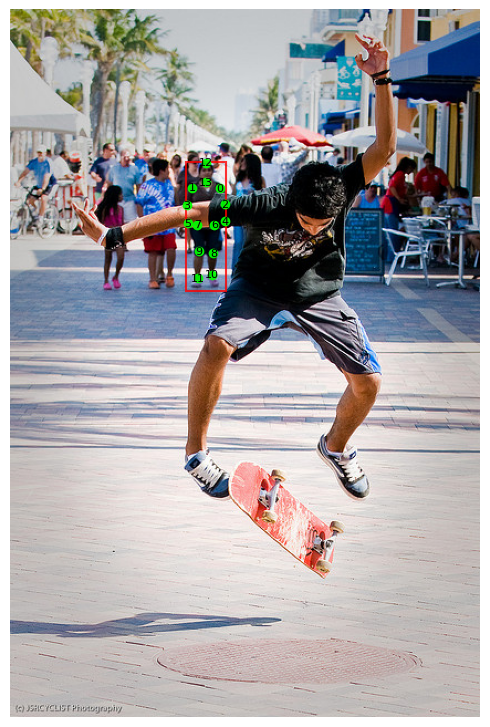

In [27]:
# Visualise predictions for a single image
sample = dataset[0]
img_tensor = torchvision.io.read_image(sample["img_path"])

ax = show_img_with_keypoints(
    img_tensor,
    keypoints=sample.get("keypoints")[1:2],
    bboxes=sample.get("bboxes")[1:2],
    numbered=True
)
keypoints = sample.get("keypoints")
#print(keypoints.shape)
mid_pt = keypoints.mean(dim=1)[0]  # Mid-hip point
plt.show()




In [ ]:
from src.data import CROWDPOSE_EDGE_LIST, make_edge_index, create_graph_from_keypoints

edge_index = make_edge_index(CROWDPOSE_EDGE_LIST)
g = create_graph_from_keypoints(edge_index, sample.get("gt_keypoints").unsqueeze(0).repeat(2, 1, 1, 1))
print(f"edge_index: {g['edge_index'].shape}")   # (2, B*N*E)
print(f"node_pos:   {g['node_pos'].shape}")     # (B*N*K, 2)
print(f"batch:      {g['batch'].shape}")        # (B*N*K,)
print(f"batch_idx:  {g['batch_idx'].shape}")    # (B, N, K)
print(f"pose_idx:   {g['pose_idx'].shape}")     # (B, N, K)

# Example: select all nodes belonging to sample b=1
b = 1
mask = g['batch_idx'].reshape(-1) == b
print(f"\nNodes for sample b={b}: {g['node_pos'][mask].shape}")  # (N*K, 2)


edge_index: torch.Size([2, 728])
node_pos:   torch.Size([364, 2])
batch:      torch.Size([364])
batch_idx:  torch.Size([2, 13, 14])
pose_idx:   torch.Size([2, 13, 14])

Nodes for sample b=1: torch.Size([182, 2])


In [18]:
dataset[0].keys()

dict_keys(['image_id', 'img_path', 'keypoints', 'keypoint_scores', 'bboxes', 'bbox_scores'])

In [ ]:
# Build DataLoader — batches are grouped by number of people so no padding is needed
loader = dataset.create_dataloader(batch_size=16, shuffle=True, drop_last=False)

print(f"Total batches: {len(loader)}")

batch = next(iter(loader))
print(f"\nExample batch:")
print(f"  Images:          {len(batch['image_ids'])}")
print(f"  Keypoints shape: {batch['keypoints'].shape}  — (B, N, K, 2)")


Total batches: 560

Example batch:
  Images:          1
  Keypoints shape: torch.Size([1, 85, 14, 2])  — (B, N, K, 2)


In [42]:
# Iterate through a few batches — N is uniform within each batch
for batch_idx, batch in enumerate(loader):
    B, N, K, _ = batch["keypoints"].shape
    print(f"Batch {batch_idx}: B={B} images × N={N} people  →  keypoints {tuple(batch['keypoints'].shape)}")


Batch 0: B=1 images × N=85 people  →  keypoints (1, 85, 14, 2)
Batch 1: B=16 images × N=4 people  →  keypoints (16, 4, 14, 2)
Batch 2: B=16 images × N=2 people  →  keypoints (16, 2, 14, 2)
Batch 3: B=2 images × N=88 people  →  keypoints (2, 88, 14, 2)
Batch 4: B=16 images × N=4 people  →  keypoints (16, 4, 14, 2)
Batch 5: B=16 images × N=23 people  →  keypoints (16, 23, 14, 2)
Batch 6: B=16 images × N=3 people  →  keypoints (16, 3, 14, 2)
Batch 7: B=16 images × N=3 people  →  keypoints (16, 3, 14, 2)
Batch 8: B=16 images × N=11 people  →  keypoints (16, 11, 14, 2)
Batch 9: B=2 images × N=56 people  →  keypoints (2, 56, 14, 2)
Batch 10: B=16 images × N=3 people  →  keypoints (16, 3, 14, 2)
Batch 11: B=16 images × N=9 people  →  keypoints (16, 9, 14, 2)
Batch 12: B=16 images × N=12 people  →  keypoints (16, 12, 14, 2)
Batch 13: B=16 images × N=3 people  →  keypoints (16, 3, 14, 2)
Batch 14: B=16 images × N=5 people  →  keypoints (16, 5, 14, 2)
Batch 15: B=16 images × N=4 people  →  keypo

In [ ]:
from dataclasses import dataclass


@dataclass
class KeypointDiffusionConfig:
    name: str
    dim_node: int = 128



class KeypointDiffusionModel(torch.nn.Module):
    def __init__(self, config: KeypointDiffusionConfig, num_keypoints: int, edge_list):
        super().__init__()
        self.config = config
        self.num_keypoints = num_keypoints
        self.edge_index = make_edge_index(edge_list)

        self.position_embedding = torch.nn.Linear(2, config.dim_node)

    def forward(self, keypoints):
        # keypoints: (B, N, K, 2)
        B, N, K, _ = keypoints.shape
        x = keypoints.view(B, N * K, 2)  # (B, N*K, 2)
        edge_index = self.edge_index.repeat(1, N) + torch.arange(N).repeat_interleave(self.edge_index.shape[1]) * self.num_keypoints
        x = self.position_embedding(x)  # (B, N*K, D)
